# Quantum Railways · Guided lab
**FreeYaMind Campus · Beginner challenge · About 3 hours for the core**

Choose fictional Romanian railway routes, turn plans into an energy model, and build QAOA to investigate its answers. Complete **A–C, F and G**, optimise locally, then compile once and compare ideal with local noisy samples. Keep your predictions and conclusions here.

**Optional:** D/E mathematical derivations, real-QPU execution and the hardware appendix take additional time. Working conversions are supplied on the core path; a carefully explained core lab is a valid beginner submission.

> This is a fictionalized optimization map created for the hackathon. Costs, routes, and rewards do not represent actual Romanian railway infrastructure or policy recommendations.

City locations are geographic; connections, costs and values are fictional.

## 0. Prepare the environment
Run this cell first in Colab or a local notebook interface. It detects Colab, installs **only mismatched or missing tested versions**, prints the versions and performs a small smoke test. It needs internet only when installation is required.

If an already imported library was replaced, restart the runtime/kernel and run this cell again. Colab and local interfaces can have different preinstalled packages; use the tested versions below rather than silently mixing them. No repository clone, local assets, Drive mount or credentials are needed for the local path.

In [32]:
import sys, subprocess, importlib.metadata as metadata
from pathlib import Path
import json
try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
TESTED_VERSIONS = {'qiskit': '2.1.0', 'qiskit-aer': '0.17.0', 'numpy': '2.2.6', 'scipy': '1.15.3', 'networkx': '3.5', 'matplotlib': '3.10.3'}

def ensure_environment(pins, installer=subprocess.check_call):
    missing=[];loaded_changes=[]
    for name,version in pins.items():
        try: current=metadata.version(name)
        except metadata.PackageNotFoundError: current=None
        if current!=version:
            missing.append(f'{name}=={version}')
            root=name.replace('-','_')
            if root in sys.modules: loaded_changes.append(root)
    if missing:
        installer([sys.executable,'-m','pip','install','--quiet',*missing])
    if loaded_changes:
        raise RuntimeError('Restart the runtime/kernel: an imported package was replaced. Then rerun this cell.')
    actual={name:metadata.version(name) for name in pins}
    assert actual==pins,'Environment versions differ; restart and rerun setup.'
    return actual

installed_versions=ensure_environment(TESTED_VERSIONS)
print('Colab' if IN_COLAB else 'Local notebook', '| Python',sys.version.split()[0])
for name,version in installed_versions.items(): print(name,version)
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import minimize
from IPython.display import display,Markdown
from qiskit import QuantumCircuit,ClassicalRegister,transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.providers.fake_provider import GenericBackendV2
smoke=QuantumCircuit(1);smoke.h(0)
assert np.allclose(Statevector.from_instruction(smoke).probabilities(),[.5,.5])
assert GenericBackendV2(num_qubits=2,seed=2026).num_qubits==2
plt.rcParams.update({'font.family':'DejaVu Sans','figure.dpi':110})
print('Import and statevector smoke test passed.')

Local notebook | Python 3.12.10
qiskit 2.1.0
qiskit-aer 0.17.0
numpy 2.2.6
scipy 1.15.3
networkx 3.5
matplotlib 3.10.3
Import and statevector smoke test passed.


## 1. A route-building board game
A route is one buildable connection between two cities; a path may use several routes. Choose any subset of the five demo routes. Add their construction costs and railway values. Your plan is **feasible** only if cost is at most the budget. Disconnected tracks are allowed in this introductory game. Destination connectivity is a later project idea, not a rule secretly included here.

**Before coding:** choose a small plan by hand. Write its route IDs, total cost, total value and validity. Encode it as five bits, in the route order shown below. Predict whether choosing the highest-value route first must be a good strategy.

In [33]:
# Geographic longitude/latitude is embedded here; route data is fictional. No map service or local file is needed.
POSITIONS = {'Iași': (27.6, 47.16667), 'București': (26.10626, 44.43225), 'Cluj-Napoca': (23.6, 46.76667), 'Timișoara': (21.22571, 45.75372), 'Brașov': (25.60613, 45.64861), 'Sibiu': (24.15, 45.8), 'Craiova': (23.8, 44.31667), 'Constanța': (28.63432, 44.18073)}
EDGE_DATA = [('Iași', 'Brașov', 2, 4), ('Iași', 'Cluj-Napoca', 3, 6), ('Cluj-Napoca', 'Brașov', 2, 5), ('Timișoara', 'Cluj-Napoca', 4, 7), ('Timișoara', 'Sibiu', 3, 6), ('Sibiu', 'Brașov', 2, 4), ('Brașov', 'București', 4, 9), ('Sibiu', 'Craiova', 2, 4), ('București', 'Constanța', 4, 7), ('Craiova', 'București', 2, 5), ('Cluj-Napoca', 'Sibiu', 2, 4), ('Iași', 'Constanța', 6, 11)]
ROUTES=[dict(id=i,cities=(u,v),cost=c,value=value) for i,(u,v,c,value) in enumerate(EDGE_DATA)]
DEMO_IDS=[0,1,2,6,8]
demo_routes=[ROUTES[i] for i in DEMO_IDS]
BUDGET=7
WEAK_PENALTY=0.7
SEED=2026
N_DECISIONS=len(demo_routes)
MATHEMATICAL_DEEP_DIVE=False  # Optional D/E derivation exercises.


In [34]:

# @title Provided helper code — maps, tables and count decoding
TEAL, CORAL, GOLD, NAVY, GREY = '#008d83', '#d2554b', '#c18a18', '#17334a', '#bac3c9'

def all_bitstrings(n):
    return [[(k >> i) & 1 for i in range(n)] for k in range(2**n)]

def decode_key(key, n):
    key = key.replace(' ', '')
    if len(key) != n or set(key) - {'0', '1'}:
        raise ValueError('Expected a measured key with exactly n binary bits')
    return [int(c) for c in key[::-1]]

def show_table(headers, rows):
    def cell(x): return str(x).replace('|', '/').replace('\n', ' ')
    display(Markdown('| ' + ' | '.join(map(cell, headers)) + ' |\n| ' +
        ' | '.join(['---']*len(headers)) + ' |\n' +
        '\n'.join('| '+' | '.join(map(cell,row))+' |' for row in rows)))

def draw_board(selected_ids=(), valid=True, title='Romanian cities • fictional connections', ax=None, routes=None, positions=None):
    routes=ROUTES if routes is None else routes
    positions=POSITIONS if positions is None else positions
    by_id={r['id']:r for r in routes}
    if ax is None: _, ax = plt.subplots(figsize=(9, 5.5))
    g=nx.Graph(); g.add_nodes_from(positions)
    g.add_edges_from(r['cities'] for r in routes)
    nx.draw_networkx_edges(g, positions, edge_color=GREY, width=1.5, ax=ax)
    if selected_ids:
        nx.draw_networkx_edges(g, positions, edgelist=[by_id[i]['cities'] for i in selected_ids],
                              edge_color=TEAL if valid else CORAL, width=4, ax=ax)
    nx.draw_networkx_nodes(g,positions,node_size=90,node_color='white',edgecolors=NAVY,ax=ax)
    nx.draw_networkx_labels(g,{n:(x,y+.12) for n,(x,y) in positions.items()},
                           font_size=9,font_family='DejaVu Sans',font_color=NAVY,ax=ax)
    nx.draw_networkx_edge_labels(g,positions,
        edge_labels={r['cities']:f"{r['id']}: {r['cost']}" for r in routes},
        font_size=8,font_color=GOLD,ax=ax)
    ax.set_title(title,color=NAVY); ax.margins(.14); ax.set_axis_off()
    ax.set_aspect(1/np.cos(np.deg2rad(np.mean([lat for lon,lat in positions.values()]))))
    return ax

def analyse_plan(bits, routes, budget, energy_function):
    if len(bits)!=len(routes) or any(b not in (0,1) for b in bits):
        raise ValueError('One binary decision is required per route')
    selected=selected_routes(bits,routes)
    cost=construction_cost(bits,routes); value=railway_value(bits,routes)
    feasible=is_feasible(bits,routes,budget)
    assert [r['id'] for r in selected]==[r['id'] for b,r in zip(bits,routes) if b]
    assert cost==sum(r['cost'] for r in selected)
    assert value==sum(r['value'] for r in selected)
    assert feasible==(cost<=budget)
    return dict(bits=list(bits),key=''.join(map(str,bits[::-1])),
                route_ids=[r['id'] for r in selected],cost=cost,score=value,
                feasible=bool(feasible),energy=float(energy_function(bits)))

def show_plans(rows):
    show_table(['Plan in decision order','Measured key','Route IDs','Cost','True score','Energy','Feasible'],
        [(r['bits'],r['key'],r['route_ids'],r['cost'],r['score'],round(r['energy'],3),r['feasible']) for r in rows])

def plot_distribution(counts, routes, budget, title='Sample probabilities'):
    n=len(routes); keys=[format(k,f'0{n}b') for k in range(2**n)]
    total=sum(counts.values())
    if total<=0: raise ValueError('No shots to plot')
    for key in counts:decode_key(key,n)
    fig,ax=plt.subplots(figsize=(11,3.8))
    ax.bar(keys,[counts.get(k,0)/total for k in keys],
        color=[TEAL if is_feasible(decode_key(k,n),routes,budget) else CORAL for k in keys])
    ax.axhline(1/len(keys),ls='--',color=NAVY,label='Uniform distribution')
    ax.set(title=title,xlabel='Measured key (variable 0 at right)',ylabel='Fraction of shots')
    if n>6:ax.set_xticks(range(0,len(keys),max(1,len(keys)//16)))
    ax.tick_params(axis='x',rotation=90,labelsize=8);ax.legend();fig.tight_layout()
    return fig

def distribution_metrics(counts, routes, budget, reference_rows):
    # Energy and target score come from this scenario's explicitly supplied reference.
    n=len(routes); by_key={r['key']:r for r in reference_rows}
    expected={format(k,f'0{n}b') for k in range(2**n)}
    if len(reference_rows)!=len(expected) or set(by_key)!=expected:
        raise ValueError('Recompute a complete reference for this decision set')
    for row in reference_rows:
        bits=decode_key(row['key'],n)
        if (row['bits']!=bits or row['cost']!=construction_cost(bits,routes)
            or row['score']!=railway_value(bits,routes)
            or row['route_ids']!=[r['id'] for r in selected_routes(bits,routes)]
            or row['feasible']!=is_feasible(bits,routes,budget)):
            raise ValueError('Reference does not match these routes/budget; recompute it')
    total=sum(counts.values())
    if total<=0 or any(n<0 for n in counts.values()):raise ValueError('Expected nonnegative counts and at least one shot')
    evaluated=[]
    for key,count in counts.items():
        decode_key(key,n);evaluated.append((count,by_key[key]))
    valid=[(count,r) for count,r in evaluated if r['feasible']]
    minimum=min(r['energy'] for r in reference_rows)
    target=max((r['score'] for r in reference_rows if r['feasible']),default=None)
    return dict(shots=total,feasible_rate=sum(count for count,r in valid)/total,
        over_budget_rate=sum(count for count,r in evaluated if not r['feasible'])/total,
        model_minimum_probability=sum(count for count,r in evaluated if np.isclose(r['energy'],minimum))/total,
        optimal_feasible_probability=sum(count for count,r in valid if r['score']==target)/total,
        mean_true_score=sum(count*r['score'] for count,r in evaluated)/total,
        expected_energy=sum(count*r['energy'] for count,r in evaluated)/total,
        best_feasible_score=max((r['score'] for count,r in valid),default=None))


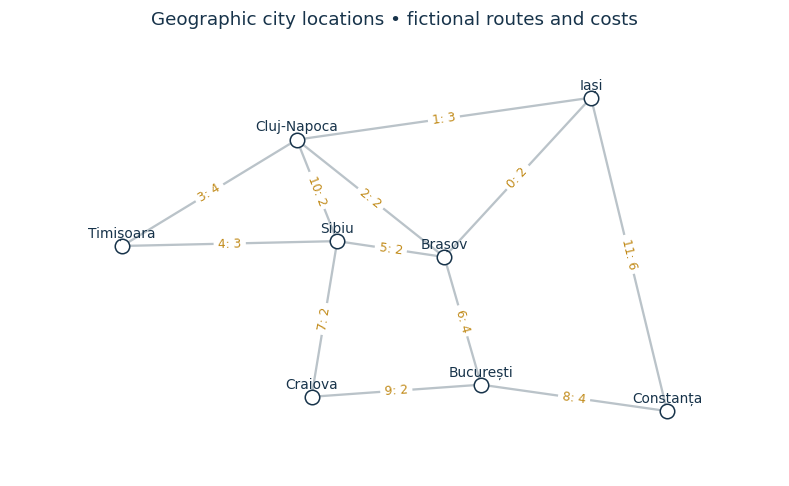

| Decision | Physical route ID | Connection | Cost | Value |
| --- | --- | --- | --- | --- |
| x0 | 0 | Iași–Brașov | 2 | 4 |
| x1 | 1 | Iași–Cluj-Napoca | 3 | 6 |
| x2 | 2 | Cluj-Napoca–Brașov | 2 | 5 |
| x3 | 6 | Brașov–București | 4 | 9 |
| x4 | 8 | București–Constanța | 4 | 7 |

In [35]:
draw_board(title='Geographic city locations • fictional routes and costs');plt.show()
show_table(['Decision','Physical route ID','Connection','Cost','Value'],
    [(f'x{i}',r['id'],'–'.join(r['cities']),r['cost'],r['value']) for i,r in enumerate(demo_routes)])
my_plan=[1,1,1,0,0]  # Change this to your hand-selected plan.
# Prediction (edit this Markdown or add a cell): cost __, value __, feasible __.


## 2. Binary decisions · Exercise A
In a plan list, bit `i` controls entry `i` of `demo_routes`. `x3` therefore controls physical route ID 6. A 1 builds it and a 0 leaves it unselected. All following functions receive routes **in decision order**, not every route on the full board.

Complete these four small functions. The checks use easy examples to detect indexing, value/cost and boundary mistakes. Then apply them to your hand-selected plan.

<details><summary>Hint 1: selection and totals</summary>Pair each bit with its route using the same index or `zip`. Include a route only when its bit is 1. Sum the selected `cost` or `value` fields.</details>
<details><summary>Hint 2: feasibility</summary>A plan spending exactly the budget is valid. Compare construction cost with the budget using “at most”, not “less than”.</details>

In [36]:

def selected_routes(bits, routes):
    selected = []

    for i in range(len(bits)):
        if bits[i] == 1:
            selected.append(routes[i])

    return selected

def construction_cost(bits,routes):
    # TODO: sum the construction costs of selected routes.
    return sum(route['cost'] for route in selected_routes(bits, routes))

def railway_value(bits, routes):
    total_value = 0
    for i in range(len(bits)):
        if bits[i] == 1:
            total_value = total_value + routes[i]['value']

    return total_value

def is_feasible(bits, routes, budget):
    cost = construction_cost(bits, routes)

    if cost <= budget:
        return True
    else:
        return False
    
assert selected_routes([1,0,0,0,0],demo_routes)==[demo_routes[0]], 'Exercise A: select routes whose bits are 1.'
assert construction_cost([1,0,0,0,0],demo_routes)==2, 'Exercise A: sum selected costs.'
assert railway_value([1,0,0,0,0],demo_routes)==4, 'Exercise A: sum selected values.'
assert is_feasible([1,0,0,0,0],demo_routes,2) is True, 'An exact-budget plan is feasible.'
assert is_feasible([1,0,0,0,0],demo_routes,1) is False, 'Do not accept an over-budget plan.'
print('Our hand-selected plan:',my_plan,'cost',construction_cost(my_plan,demo_routes),
      'value',railway_value(my_plan,demo_routes),'feasible',is_feasible(my_plan,demo_routes,BUDGET))


Our hand-selected plan: [1, 1, 1, 0, 0] cost 7 value 15 feasible True


## 3. Give plans an energy · Exercise B
Useful routes should **reduce** energy. Spending away from the budget should increase this starter model's penalty. This approximation targets exact spending; investigate whether that faithfully describes the “at most” rule.

**Predict before implementing:** with no penalty, what will the model want? With a weak penalty, could extra value outweigh overspending? Could a very large penalty have disadvantages? Must the energy minimum be valid?

Complete a model with a negative value term and a squared distance-from-budget penalty, weighted by `penalty`. Keep the real score and feasibility functions separate from energy.

<details><summary>Hint 1: signs and weight</summary>Higher value should give lower energy, so use a negative value term. A penalty weight multiplies the squared cost difference.</details>
<details><summary>Hint 2: mathematical model</summary>
$$E(x)=-V(x)+\lambda(C(x)-B)^2.$$
The square also penalises underspending. It is not a hard general encoding of $C(x)\le B$.
</details>

In [37]:
def model_energy(bits, routes, budget, penalty):

    # Calculam punctele obtinute
    value = railway_value(bits, routes)

    # Calculam cat costa rutele
    cost = construction_cost(bits, routes)

    # Calculam diferenta fata de buget
    difference = cost - budget

    # Calculam penalizarea
    penalty_value = penalty * (difference ** 2)

    # Calculam energia finala
    energy = -value + penalty_value

    return energy


assert model_energy([0]*5,demo_routes,BUDGET,WEAK_PENALTY) is not None, 'Exercise B: return the energy.'
assert np.isclose(model_energy([0]*5,demo_routes,7,0),0), 'No routes and no penalty gives zero.'
assert np.isclose(model_energy([1,0,0,0,0],demo_routes,2,.7),-4), 'Exact spending has no penalty.'


## 4. Enumerate the tiny instance · Exercise C
There are only $2^5=32$ plans. Complete the loop to evaluate them all using `analyse_plan(bits, demo_routes, BUDGET, energy_function)`. This helper validates selected routes, actual totals and feasibility using your functions.

The provided `energy_for_plan` function fixes the scenario and current penalty for each call. Then inspect the **lowest-energy** plan and **best feasible true-score** plan. Are they the same? Explore penalties 0, 0.7 and 4.0. Write what changes and what stays fixed.

<details><summary>Hint 1</summary>`all_bitstrings(n)` supplies every plan in x0…x(n−1) list order. Append one analysed row per plan.</details>
<details><summary>Hint 2</summary>Minimise the `energy` field for the model answer. Filter `feasible` rows before maximising `score` for the game answer.</details>

In [38]:

def enumerate_demo_plans(penalty):

    # Functia care calculeaza energia unui plan
    def energy_for_plan(bits):
        return model_energy(bits, demo_routes, BUDGET, penalty)

    # Lista in care pastram rezultatele
    rows = []

    # Generam toate cele 32 de combinatii
    for bits in all_bitstrings(5):

        # Analizam planul curent
        plan = analyse_plan(bits,demo_routes,BUDGET,energy_for_plan)

        # Adaugam rezultatul in lista
        rows.append(plan)

    return rows


classical_rows=enumerate_demo_plans(WEAK_PENALTY)
assert len(classical_rows)==32, 'Exercise C: evaluate all 32 plans, not just valid ones.'
assert len({r['key'] for r in classical_rows})==32, 'Every plan must occur exactly once.'
qubo_best=min(classical_rows,key=lambda r:r['energy'])
classical_best=max((r for r in classical_rows if r['feasible']),key=lambda r:r['score'])
show_plans([qubo_best,classical_best])
# TODO: use enumerate_demo_plans with other weights; choose a useful table or plot.
# Record separately: did we minimise energy, and did energy encode our intended rule?

for penalty in [0, 0.7, 4.0]:

    # Analizam cele 32 de planuri
    plans = enumerate_demo_plans(penalty)

    # Gasim planul cu energia cea mai mica
    best = min(plans, key=lambda plan: plan['energy'])

    # Afisam rezultatele
    print("Penalizare:", penalty)
    print("Rute:", best['bits'])
    print("Cost:", best['cost'])
    print("Puncte:", best['score'])
    print("Energie:", best['energy'])
    print("Valid:", best['feasible'])
    print("-------------------")

| Plan in decision order | Measured key | Route IDs | Cost | True score | Energy | Feasible |
| --- | --- | --- | --- | --- | --- | --- |
| [1, 0, 1, 1, 0] | 01101 | [0, 2, 6] | 8 | 18 | -17.3 | False |
| [1, 1, 1, 0, 0] | 00111 | [0, 1, 2] | 7 | 15 | -15.0 | True |

Penalizare: 0
Rute: [1, 1, 1, 1, 1]
Cost: 15
Puncte: 31
Energie: -31.0
Valid: False
-------------------
Penalizare: 0.7
Rute: [1, 0, 1, 1, 0]
Cost: 8
Puncte: 18
Energie: -17.3
Valid: False
-------------------
Penalizare: 4.0
Rute: [1, 1, 1, 0, 0]
Cost: 7
Puncte: 15
Energie: -15.0
Valid: True
-------------------


## 5. Understand the supplied conversion · optional Exercise D
Binary bits obey $x_i^2=x_i$. Expanding the square in the energy gives
$$E(x)=a_0+\sum_i a_ix_i+\sum_{i<j}b_{ij}x_ix_j.$$
The value contributes linear terms. The squared cost introduces both linear terms and interactions between decisions. Store each pair **once**, in the upper triangle of `quadratic`.

Core path: read the supplied coefficients and run the check. Optionally derive one linear coefficient and one interaction before attempting the full arrays.

Optional deep dive: set `MATHEMATICAL_DEEP_DIVE=True` near the board data and complete the full coefficient arrays. The hints unpack the cost square.

<details><summary>Hint 1: linear terms</summary>Combine negative value, the cost-square diagonal using $x_i^2=x_i$, and the $-2B$ cross term.</details>
<details><summary>Hint 2: pair terms</summary>For $i<j$, the cost square contributes $2\lambda c_i c_j$. Set diagonal/lower-triangle entries to zero.</details>

In [39]:
def construct_qubo(routes, budget, penalty):
    costs = np.array([r['cost'] for r in routes], float)
    values = np.array([r['value'] for r in routes], float)

    linear = -values + penalty * (costs**2 - 2*budget*costs)

    quadratic = np.triu(2*penalty*np.outer(costs, costs), 1)

    if MATHEMATICAL_DEEP_DIVE:
        linear = -values + penalty * (costs**2 - 2*budget*costs)
        quadratic = np.triu(2*penalty*np.outer(costs, costs), 1)

    return dict(
        offset=penalty * budget**2,
        linear=linear,
        quadratic=quadratic
    )

qubo=construct_qubo(demo_routes,BUDGET,WEAK_PENALTY)
assert qubo['linear'] is not None and qubo['quadratic'] is not None, 'Exercise D: supply both coefficient arrays.'
assert np.shape(qubo['linear'])==(N_DECISIONS,) and np.shape(qubo['quadratic'])==(N_DECISIONS,N_DECISIONS)
assert np.allclose(qubo['quadratic'],np.triu(qubo['quadratic'],1)), 'Count each pair exactly once.'
def qubo_energy(bits,q=qubo):
    x=np.array(bits)
    return float(q['offset']+q['linear']@x+x@q['quadratic']@x)
for bits in all_bitstrings(N_DECISIONS):
    assert np.isclose(qubo_energy(bits),model_energy(bits,demo_routes,BUDGET,WEAK_PENALTY)), 'Direct and quadratic energy disagree.'
print('Direct and QUBO energies agree on every plan.')


Direct and QUBO energies agree on every plan.


### From a bit to a Z eigenvalue · optional Exercise E
The operator $Z$ assigns $+1$ to bit 0 and $-1$ to bit 1, so use $x_i=(1-Z_i)/2$. A cost Hamiltonian assigns **the same energy** to the corresponding qubit basis state.

For upper-triangle pair coefficients $b_{ij}$:
$$J_{ij}=b_{ij}/4,\qquad h_i=-a_i/2-\tfrac14\sum_{j\ne i}b_{\min(i,j),\max(i,j)},$$
$$C=a_0+\tfrac12\sum_i a_i+\tfrac14\sum_{i<j}b_{ij}.$$
Core path: read the supplied transformation and run its check. Optional deep dive: derive `h`, the coefficient of each $Z_i$, with `MATHEMATICAL_DEEP_DIVE=True`. Each interaction shifts **both endpoints**.

<details><summary>Hint</summary>For each variable, add the sum of its row and its column in the upper-triangle matrix, divide by four, and subtract it along with half its linear coefficient.</details>

In [40]:
def qubo_to_ising(q):
    a,b=q['linear'],q['quadratic']
    h=-a/2-(b.sum(axis=0)+b.sum(axis=1))/4
    if MATHEMATICAL_DEEP_DIVE:
        h = -a/2 - (b.sum(axis=0) + b.sum(axis=1))/4
    return dict(constant=float(q['offset']+a.sum()/2+b.sum()/4),h=h,J=b/4)

ising=qubo_to_ising(qubo)
assert ising['h'] is not None, 'Exercise E: supply the Z coefficients.'
for bits in all_bitstrings(N_DECISIONS):
    z=1-2*np.array(bits)
    eig=ising['constant']+ising['h']@z+z@ising['J']@z
    assert np.isclose(eig,qubo_energy(bits)), 'Hamiltonian eigenvalue does not match the classical energy.'
print('Direct, QUBO and Hamiltonian energies agree on all 32 states.')


Direct, QUBO and Hamiltonian energies agree on all 32 states.


## 6. Build QAOA · Exercise F
QAOA does not make a system simply fall into a lowest-energy state.

- Hadamards prepare an initial superposition of candidate bitstrings.
- The **cost operation** $e^{-i\gamma H_C}$ changes phases according to model energy; phases alone do not change the measurement probabilities.
- The **mixer** $e^{-i\beta\sum X_i}$ combines amplitudes. Interference reshapes probabilities.
- Depth $p$ repeats cost and mixer layers with their own angles. A classical optimiser adjusts the angles to reduce **expected model energy**.
- Measurement samples the final distribution. Neither optimum nor feasibility is guaranteed.

Implement the cost and mixer layers. `rz(2t)` represents $e^{-itZ}$ and `rzz(2t)` represents $e^{-itZZ}$; `rx(2t)` represents $e^{-itX}$. The constant is only a global phase. We divide cost coefficients by a scale to keep angles manageable; this does not change energy ranking.

The circuit factory handles symbols and repetition, but stays visible. You will later preserve these same parameter objects through transpilation.

<details><summary>Hint 1: cost</summary>Use one RZ for each `h[i]` and one RZZ for each nonzero upper-triangle `J[i,j]`; multiply the coefficient by gamma/scale and by two.</details>
<details><summary>Hint 2: mixer</summary>Apply RX with angle `2*beta` to each decision qubit.</details>

In [41]:
def add_cost(qc, gamma, ising):

    h = ising['h']
    J = ising['J']

    # Calculam o valoare pentru a tine unghiurile mai mici
    scale = max(1, np.max(np.abs(h)), np.max(np.abs(J)))

    # Trecem prin fiecare qubit
    for i in range(len(h)):

        # Calculam unghiul pentru acest qubit
        unghi = 2 * gamma * h[i] / scale

        # Aplicam poarta RZ
        qc.rz(unghi, i)

    # Trecem prin toate perechile de qubiti
    for i in range(len(h)):

        for j in range(i + 1, len(h)):

            # Verificam daca perechea are o contributie
            if J[i][j] != 0:

                # Calculam unghiul pentru pereche
                unghi = 2 * gamma * J[i][j] / scale

                # Aplicam poarta RZZ pe cei doi qubiti
                qc.rzz(unghi, i, j)

    # Trimitem circuitul modificat inapoi
    return qc

def add_mixer(qc, beta):

    # Trecem prin fiecare qubit
    for i in range(qc.num_qubits):

        # Aplicam poarta RX
        qc.rx(2 * beta, i)

    # Returnam circuitul
    return qc

def parameterized_qaoa(q,p=1,measure=False):
    n=len(q['linear']);parameters=ParameterVector('theta',2*p)
    qc=QuantumCircuit(n);qc.h(range(n))
    for layer in range(p):
        add_cost(qc,parameters[2*layer],qubo_to_ising(q))
        add_mixer(qc,parameters[2*layer+1])
    if measure:
        register=ClassicalRegister(n,'plan');qc.add_register(register)
        qc.measure(range(n),register)
    return qc,list(parameters)

phase_test=QuantumCircuit(N_DECISIONS);phase_test.h(range(N_DECISIONS));add_cost(phase_test,.31,ising)
state=np.asarray(Statevector.from_instruction(phase_test))
scale=max(1.,np.max(np.abs(ising['h'])),np.max(np.abs(ising['J'])))
expected=np.exp(-1j*.31*np.array([qubo_energy(bits) for bits in all_bitstrings(N_DECISIONS)])/scale)
assert np.allclose(state/state[0],expected/expected[0]), 'Exercise F: cost phases must depend on the model energy.'
np.testing.assert_allclose(np.abs(state)**2,np.ones(2**N_DECISIONS)/2**N_DECISIONS,atol=1e-12)
mix_test=QuantumCircuit(1);add_mixer(mix_test,.3)
assert np.isclose(Statevector.from_instruction(mix_test).probabilities()[1],np.sin(.3)**2), 'Exercise F: check your mixer.'
P=1
logical_circuit,logical_parameters=parameterized_qaoa(qubo,p=P)
print('QAOA parameters:',[p.name for p in logical_parameters])


QAOA parameters: ['theta[0]', 'theta[1]']


## 7. Optimise angles locally · Exercise G
First inspect the zero-angle starting distribution. Then complete the expected-energy function. Aer/statevector simulation here computes exact probabilities during training; **training does not use measurement shots**. Final samples will use finite shots.

The optimiser receives the average model energy, not the best observed score or a stored optimal bitstring. Lowering this average is different from guaranteeing an optimal measurement.

<details><summary>Hint</summary>The dot product of state probabilities and the classical energy array gives the expected energy. Both arrays follow integer basis-state order, which `all_bitstrings` also uses.</details>

In [42]:
energy_array=np.array([qubo_energy(bits) for bits in all_bitstrings(N_DECISIONS)])
initial_angles=np.zeros(len(logical_parameters))
def exact_probabilities(angles):
    bound=logical_circuit.assign_parameters(dict(zip(logical_parameters,angles)))
    return Statevector.from_instruction(bound).probabilities()
initial_probabilities=exact_probabilities(initial_angles)
assert np.allclose(initial_probabilities,np.ones(2**N_DECISIONS)/2**N_DECISIONS)
print('Initial probability of each plan:',initial_probabilities[0])


Initial probability of each plan: 0.031249999999999976


In [43]:

def expected_energy(angles):

    # Calculam probabilitatile celor 32 de planuri
    probabilities = exact_probabilities(angles)

    # Pornim de la zero
    total = 0

    # Trecem prin toate planurile
    for i in range(len(probabilities)):

        # Probabilitatea planului i
        probabilitate = probabilities[i]

        # Energia planului i
        energie = energy_array[i]

        # Adunam contributia planului la energia medie
        total = total + probabilitate * energie

    # Returnam energia medie
    return total


assert expected_energy(initial_angles) is not None, 'Exercise G: return a probability-weighted energy.'
assert np.isclose(expected_energy(initial_angles),np.mean(energy_array)), 'The initial uniform distribution averages all energies.'


In [44]:
# Visible loop: the shown zero-angle start, plus one seeded random restart.
from time import perf_counter
start=perf_counter();rng=np.random.default_rng(SEED);evaluations=[]
def logged_objective(angles):
    value=expected_energy(angles);evaluations.append(value);return value
starting_points=[initial_angles.copy(),rng.uniform(0,np.pi,2*P)]
trials=[minimize(logged_objective,point,method='COBYLA',
                 options={'maxiter':90,'rhobeg':.6,'tol':1e-5}) for point in starting_points]
optimum=min(trials,key=lambda r:r.fun)
best_angles=np.array(optimum.x)
training_seconds=perf_counter()-start
print('Initial expected energy:',expected_energy(initial_angles))
print('Optimised expected energy:',expected_energy(best_angles))
print('Evaluations:',len(evaluations),' | local training seconds:',round(training_seconds,3))
print('Optimiser status:',optimum.message)
# Final ideal measurement: finite shots, independent of exact-expectation training.
IDEAL_SHOTS=2048
measured_circuit=logical_circuit.copy()
plan_register=ClassicalRegister(len(demo_routes),'plan');measured_circuit.add_register(plan_register)
measured_circuit.measure(range(len(demo_routes)),plan_register)
ideal_bound=measured_circuit.assign_parameters(dict(zip(logical_parameters,best_angles)))
ideal_backend=AerSimulator(max_parallel_threads=1)
ideal_counts=dict(ideal_backend.run(transpile(ideal_bound,ideal_backend),shots=IDEAL_SHOTS,
                                   seed_simulator=SEED).result().get_counts())


Initial expected energy: -6.749999999999995
Optimised expected energy: -13.302797069864829
Evaluations: 93  | local training seconds: 0.202
Optimiser status: Optimization terminated successfully.


### Decide what evidence to show
Qiskit prints the highest-index bit on the left: the **rightmost measured bit is x0**. We measure logical decision `i` into classical register `plan[i]`; `decode_key` returns the x0…x4 plan order.

Use a plot or table to compare the initial and optimised distributions. Which outcome is most frequent? Which is the best **feasible** sample? Compare both with exact enumeration. You can use `plot_distribution(counts, routes, budget)` and `draw_board(route_ids, valid)`; choose evidence that answers your question, rather than plotting everything.

| Plan in decision order | Measured key | Route IDs | Cost | True score | Energy | Feasible |
| --- | --- | --- | --- | --- | --- | --- |
| [0, 1, 1, 1, 0] | 01110 | [1, 2, 6] | 9 | 20 | -17.2 | False |
| [1, 1, 1, 0, 0] | 00111 | [0, 1, 2] | 7 | 15 | -15.0 | True |
| [1, 0, 1, 1, 0] | 01101 | [0, 2, 6] | 8 | 18 | -17.3 | False |
| [1, 1, 1, 0, 0] | 00111 | [0, 1, 2] | 7 | 15 | -15.0 | True |

| Metric | Ideal finite-shot result |
| --- | --- |
| shots | 2048 |
| feasible_rate | 0.34766 |
| over_budget_rate | 0.65234 |
| model_minimum_probability | 0.06982 |
| optimal_feasible_probability | 0.11133 |
| mean_true_score | 16.93311 |
| expected_energy | -13.28066 |
| best_feasible_score | 15 |

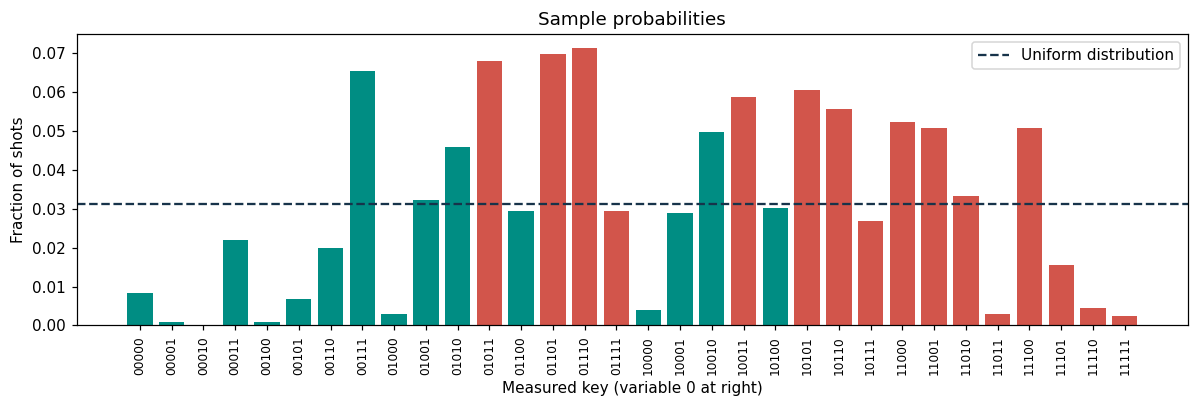

In [45]:
baseline_energy=lambda plan:model_energy(plan,demo_routes,BUDGET,WEAK_PENALTY)
sampled_rows=[analyse_plan(decode_key(key,N_DECISIONS),demo_routes,BUDGET,baseline_energy) for key in ideal_counts]
most_frequent=analyse_plan(decode_key(max(ideal_counts,key=ideal_counts.get),N_DECISIONS),demo_routes,BUDGET,baseline_energy)
best_sample=max((r for r in sampled_rows if r['feasible']),key=lambda r:r['score'],default=None)
show_plans([r for r in [most_frequent,best_sample,qubo_best,classical_best] if r is not None])
ideal_metrics=distribution_metrics(ideal_counts,demo_routes,BUDGET,classical_rows)
show_table(['Metric','Ideal finite-shot result'],[(k,round(v,5) if isinstance(v,float) else v) for k,v in ideal_metrics.items()])
# TODO: choose one useful visual and explain what it shows.
# plot_distribution(ideal_counts,demo_routes,BUDGET); plt.show()
# Add an initial-versus-optimised probability plot if it helps your explanation.

plot_distribution(ideal_counts, demo_routes, BUDGET)
plt.show()


## 8. Interpret before going to a backend
- Did QAOA produce low-energy samples? Compare its distribution with exact enumeration.
- Was the model minimum feasible? Separate a model failure from an optimisation failure.
- Which feasible plan would you choose, and could finite sampling change your conclusion?

Mean true score includes invalid outcomes; report feasibility separately. Uniform sampling can also find an optimum in this tiny space. This is not evidence of quantum advantage.

## 9. Compile once and run locally
We optimised the angles locally. Now we compile that **fixed final circuit** for a target backend. Compilation translates gates and maps logical decisions to physical qubits, changing depth and gate count.

The default synthetic device samples locally with generated noise: no IBM package, credentials or network is needed. It is neither a real QPU result nor a prediction of a current device.

In [46]:

# @title Provided local backend helpers — resources and named-register decoding
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.primitives import BackendSamplerV2

def local_backend(num_qubits):
    return GenericBackendV2(num_qubits=max(2,num_qubits),basis_gates=['id','rz','sx','x','cx'],
        coupling_map=[[i,j] for i in range(max(2,num_qubits)) for j in range(max(2,num_qubits)) if abs(i-j)==1],seed=2026)

def two_qubit_count(circuit):
    return sum(instruction.operation.num_qubits==2 for instruction in circuit.data)

def isa_resources(circuit, logical_circuit):
    used=sorted({circuit.find_bit(q).index for i in circuit.data
                 if i.operation.name not in ('barrier','delay') for q in i.qubits})
    initial=[circuit.layout.initial_layout[q] for q in logical_circuit.qubits] if circuit.layout else list(range(logical_circuit.num_qubits))
    final=circuit.layout.final_index_layout(filter_ancillas=True) if circuit.layout else initial
    return dict(depth=circuit.depth(),two_qubit_gates=two_qubit_count(circuit),physical_qubits=used,
                initial_layout=initial,final_layout=final,circuit_width=circuit.num_qubits,
                output_swap_instructions=int(circuit.count_ops().get('swap',0)))

def extract_plan_counts(pub_result, n_decisions=None):
    measured=getattr(pub_result.data,'plan',None)
    if measured is None: raise ValueError('Expected the named classical register plan')
    counts=measured.get_counts()
    width=measured.num_bits
    if n_decisions is not None and width!=n_decisions:raise ValueError('Measurement width differs from the decision set')
    for key in counts: decode_key(key,width)
    return dict(counts)


In [47]:
BACKEND_SHOTS = IDEAL_SHOTS
TRANSPILE_SEED = 2026

final_logical_circuit = measured_circuit.assign_parameters(
    dict(zip(logical_parameters, best_angles)))
assert not final_logical_circuit.parameters
backend=local_backend(N_DECISIONS)
backend_kind='Local noisy/synthetic'


In [48]:
pass_manager=generate_preset_pass_manager(
    backend=backend, optimization_level=1, seed_transpiler=TRANSPILE_SEED)
chosen_isa=pass_manager.run(final_logical_circuit)
chosen_resources=dict(optimization=1,seed=TRANSPILE_SEED,
    **isa_resources(chosen_isa,final_logical_circuit))
assert not chosen_isa.parameters
show_table(['Circuit','Depth','Two-qubit gates'],[
    ('Logical',final_logical_circuit.depth(),two_qubit_count(final_logical_circuit)),
    ('Compiled',chosen_isa.depth(),two_qubit_count(chosen_isa))])
print('Final logical-to-physical mapping:',chosen_resources['final_layout'])


| Circuit | Depth | Two-qubit gates |
| --- | --- | --- |
| Logical | 11 | 10 |
| Compiled | 53 | 34 |

Final logical-to-physical mapping: [0, 1, 4, 2, 3]


In [49]:
local_sampler=BackendSamplerV2(backend=backend,options={'seed_simulator':SEED})
local_job=local_sampler.run([chosen_isa],shots=BACKEND_SHOTS)
backend_counts=extract_plan_counts(local_job.result()[0],N_DECISIONS)
assert sum(backend_counts.values())==BACKEND_SHOTS
# Measurements still go into plan[i], even when compilation moves qubits.
# decode_key returns decision order x0, x1, …; it does not undo the physical layout.
real_counts=None
print('Local noisy samples:',sum(backend_counts.values()))


Local noisy samples: 2048


### Optional but encouraged: run the same fixed circuit on a real QPU
Skip these cells for the core. Enable `USE_REAL_HARDWARE` above only with organiser-approved access. Use `BACKEND_NAME` when assigned; leaving it empty deliberately asks for an accessible operational device. The supplied connection helper uses Colab Secrets (`IBM_QUANTUM_TOKEN`) or a masked prompt and never saves accounts. Never paste or share tokens; clear sensitive outputs before submitting.

The sequence is **select → compile the fixed circuit → Sampler → save job ID → retrieve counts**. Copy the printed job ID before waiting, so a disconnected session can recover it without resubmitting. A failed real attempt is reported, never relabelled as a local result. Real queues are outside the core timing.

In [50]:
# @title Optional IBM connection helpers
from getpass import getpass

USE_REAL_HARDWARE = False  # Optional continuation below; leave False for the core.
BACKEND_NAME = "ibm_aachen"           # Organiser-assigned name, if using a real QPU.

def modern_ibm_types():
    # No legacy live fallback. The organiser must validate the current IBM environment.
    try:
        version=metadata.version('qiskit-ibm-runtime')
        if tuple(map(int,version.split('.')[:2]))<(0,50):raise ImportError('Old client')
        from qiskit_ibm_runtime import QiskitRuntimeService
        from qiskit_ibm_runtime.executor_sampler import Sampler
    except (ImportError,metadata.PackageNotFoundError) as exc:
        raise RuntimeError('Real QPU access needs an organiser-validated current IBM client (0.50+), client-side Sampler and ibm_quantum_platform. The tested local path still works.') from None
    return QiskitRuntimeService,Sampler

def choose_backend(connect=False, assigned_name='', instance='', use_saved=False, num_qubits=5):
    """Never prompts or connects unless explicitly enabled. Does not save credentials."""
    if not connect:
        return None,local_backend(num_qubits),'synthetic backend (local noisy simulation)'
    Service,_=modern_ibm_types()
    try:
        if use_saved:
            service=Service(channel='ibm_quantum_platform',instance=instance or None)
        else:
            token=None
            try:
                from google.colab import userdata
                token=userdata.get('IBM_QUANTUM_TOKEN')
            except Exception:
                pass
            if not token: token=getpass('IBM Cloud API key (masked; not saved): ')
            try:
                service=Service(channel='ibm_quantum_platform',token=token,instance=instance or None)
            finally:
                del token
        if assigned_name:
            backend=service.backend(assigned_name)
            if backend.num_qubits<num_qubits or not backend.status().operational:
                raise ValueError('Assigned backend is unavailable or too small')
        else:
            available=service.backends(min_num_qubits=num_qubits,operational=True,simulator=False)
            if not available: raise ValueError('No accessible operational backend')
            backend=min(available,key=lambda b:b.status().pending_jobs)
        return service,backend,'real QPU'
    except Exception as exc:
        # Exception details can contain account information; never echo them.
        raise RuntimeError('Real IBM connection/discovery failed. No real result was obtained; local results remain available. Ask an organiser to check access before retrying.') from None


In [51]:
real_job_id=None
if USE_REAL_HARDWARE:
    IBM_INSTANCE=""  # Organiser-provided instance/CRN, if required.
    service,real_backend,_=choose_backend(True,BACKEND_NAME,IBM_INSTANCE,num_qubits=N_DECISIONS)
    real_isa=generate_preset_pass_manager(backend=real_backend,optimization_level=1,
                                        seed_transpiler=TRANSPILE_SEED).run(final_logical_circuit)
    _,Sampler=modern_ibm_types()
    real_job=Sampler(mode=real_backend).run([real_isa],shots=BACKEND_SHOTS)
    real_job_id=real_job.job_id()
    print('Backend:',real_backend.name,'| Job ID:',real_job_id,flush=True)
    print('Copy/save this job ID now; retrieve it rather than submit again if disconnected.',flush=True)
    real_counts=extract_plan_counts(real_job.result()[0],N_DECISIONS)
    assert sum(real_counts.values())==BACKEND_SHOTS
    print('Real compiled depth:',real_isa.depth(),'| Two-qubit gates:',two_qubit_count(real_isa))
else:
    print('Real QPU execution skipped; the core uses local results above.')


Real QPU execution skipped; the core uses local results above.


## 10. Ideal versus backend evidence
Compare the chance of a best feasible plan (including ties), any feasible plan and average **model energy**. Use the compiled resources above when interpreting changes.

- What changed from ideal to backend sampling? Was the most frequent result still feasible and useful?
- Which circuit resource or noise source might explain the change? What experiment would you run next?

Sampling, compilation and noise can all matter; this comparison alone does not isolate their effects.

| Source | P(best feasible) | P(feasible) | Expected energy |
| --- | --- | --- | --- |
| Ideal | 0.1113 | 0.3477 | -13.281 |
| Local noisy/synthetic | 0.1064 | 0.397 | -12.593 |

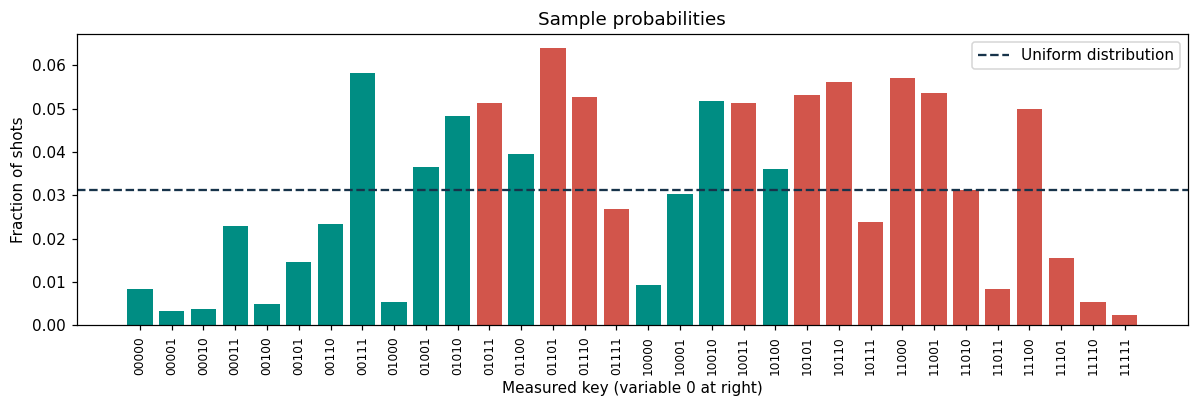

In [52]:
comparison=[('Ideal',distribution_metrics(ideal_counts,demo_routes,BUDGET,classical_rows)),
    (backend_kind,distribution_metrics(backend_counts,demo_routes,BUDGET,classical_rows))]
if real_counts is not None:
    comparison.append(('Real QPU',distribution_metrics(real_counts,demo_routes,BUDGET,classical_rows)))
comparison_headers=['Source','P(best feasible)','P(feasible)','Expected energy']
comparison_rows=[(name,round(m['optimal_feasible_probability'],4),round(m['feasible_rate'],4),
                  round(m['expected_energy'],3)) for name,m in comparison]
show_table(comparison_headers,comparison_rows)
# TODO: choose one map or distribution plot that helps explain a difference.
# plot_distribution(backend_counts,demo_routes,BUDGET); plt.show()

# Afisam distributia rezultatelor cu zgomot
plot_distribution(backend_counts, demo_routes, BUDGET)
plt.show()


## Your conclusion and next question
Write your conclusions rather than accepting a supplied answer:

**What did our model reward?** …  

Modelul nostru a favorizat planurile care aduc multe puncte și au energie mică. Am observat că penalizarea de 0,7 era prea slabă, deoarece unele planuri care depășeau bugetul aveau totuși energie mai mică decât cele valide.
De exemplu, planul [1,0,1,1,0] costă 8 și aduce 18 puncte. Cu penalizarea 0,7, energia lui este:

E = −18 + 0,7 × (8 − 7)² = −17,3
Dacă mărim penalizarea la 4,0, energia aceluiași plan devine:
E = −18 + 4 × (8 − 7)² = −14

Astfel, planul care depășește bugetul devine mai puțin avantajos pentru model. Vrem să testăm dacă o penalizare mai mare ajută QAOA să producă mai multe planuri valide.

**What did the classical reference reveal?** …  

Prin metoda clasică am verificat toate cele 32 de combinații posibile.Am descoperit că cel mai bun plan care respectă bugetul este [1,1,1,0,0], cu un cost de 7 și un punctaj de 15. În schimb, planul cu energia minimă pentru penalizarea 0,7 este [1,0,1,1,0], care are 18 puncte, dar costă 8. Deci nu respectă bugetul.

**What did QAOA change in the distribution?** …  

La început, toate cele 32 de planuri aveau aceeași probabilitate de apariție, adică 3,125%. După ce am optimizat unghiurile gamma și beta, unele planuri au început să apară mai des decât altele. Energia medie a scăzut de la aproximativ −6,75 la −13,30, ceea ce înseamnă că optimizarea a reușit să reducă energia medie a circuitului.
Totuși, acest lucru nu garantează că planurile care apar cel mai des respectă bugetul.

**What was feasible and useful?** …  

Cel mai bun plan valid pe care l-am găsit a fost [1,1,1,0,0], cu un cost de 7 și un punctaj de 15. Acest plan a fost găsit atât prin metoda clasică, cât și în măsurările QAOA. Planul care a apărut cel mai des în simularea ideală a fost însă [0,1,1,1,0], care are 20 de puncte, dar costă 9. Acesta nu respectă bugetul. Noi am alege planul cu 15 puncte, deoarece respectă bugetul și este cea mai bună variantă validă.

**What changed after compilation/backend execution?** …  

După compilare, circuitul a devenit mai complex. Adâncimea a crescut de la 11 la 53, iar numărul de porți pe doi qubiți de la 10 la 34. Am comparat apoi simularea ideală cu simularea locală cu zgomot. În simularea ideală, 34,77% dintre planuri respectau bugetul. În cea cu zgomot, procentul a ajuns la 39,70%. În schimb, probabilitatea planului optim valid a scăzut puțin, de la 11,13% la 10,64%. Energia medie a crescut de la −13,281 la −12,593, deci rezultatul a fost puțin mai slab din punctul de vedere al minimizării energiei.
Am observat astfel că rezultatele se pot schimba după compilare și introducerea zgomotului. Nu putem spune însă că toate diferențele sunt cauzate numai de zgomot.

**What evidence supports our explanation?** …  

Pentru a ne verifica rezultatele, am folosit tabelele și graficele din laborator. În Exercițiul C am analizat toate cele 32 de combinații și am găsit cel mai bun plan valid, cu un cost de 7 și 15 puncte. În Exercițiul G am observat că energia medie a scăzut de la −6,75 la −13,30 după optimizare. Totuși, doar 34,77% dintre planurile măsurate respectau bugetul. Am comparat și simularea ideală cu cea cu zgomot, unde procentul planurilor valide a fost de 39,70%.Rezultatele ne arată că QAOA a reușit să reducă energia medie, dar nu a garantat respectarea bugetului.

**What limitation or research question would we investigate next?** …

Principala problemă observată a fost penalizarea de 0,7, care nu era suficient de mare pentru a descuraja planurile care depășeau bugetul.
În continuare, am vrea să testăm o penalizare de 4,0 și să vedem dacă obținem mai multe planuri valide. De exemplu, un plan cu 18 puncte și costul 8 are energia −17,3 pentru penalizarea 0,7, dar energia −14 pentru penalizarea 4,0. Am vrea să comparăm rezultatele QAOA pentru cele două penalizări și să vedem dacă planul optim valid apare mai des.

The optimiser follows the model it receives. Did your energy express the planning problem you intended?

After the lab, follow the project workflow and compact idea bank in `PARTICIPANT_GUIDE.md`. Make one meaningful change, retain a genuine quantum component, compare with a classical reference, and communicate the evidence. A careful negative result is valuable. A beginner team completing the lab with genuine understanding can also submit its investigation.=

## Extension workspace
Keep the completed lab as your unchanged baseline, then investigate **one** question here or in a copy.

**Our question:** Dacă mărim penalizarea de la 0,7 la 4,0, vom obține mai multe planuri care respectă bugetul?

**Our prediction:** Credem că o penalizare mai mare va descuraja planurile care depășesc bugetul și ar putea crește procentul planurilor valide.

**Our unchanged baseline:** Păstrăm rezultatele inițiale cu 5 rute, bugetul 7, penalizarea 0,7 și un strat QAOA.

**What we will change:** Vom modifica doar penalizarea, de la 0,7 la 4,0. Restul setărilor rămân aceleași.

**Our classical reference:** Vom verifica toate cele 32 de combinații și vom compara planul cu energia minimă cu cel mai bun plan valid.

**Evidence we will collect:** Vom compara energia medie, procentul planurilor valide și cât de des apare planul optim valid pentru cele două penalizări.

These helpers take the scenario explicitly. If you change routes, budget or energy, recompute the reference before measuring success. Start small enough to enumerate. The default score is still additive route value; a new true scoring rule needs a matching evaluator. No extension algorithm is solved for you here.

In [53]:
# @title Provided extension helpers — explicit inputs, no five-route constants
def enumerate_plans(routes,budget,energy_function):
    return [analyse_plan(bits,routes,budget,energy_function) for bits in all_bitstrings(len(routes))]

def build_qaoa(qubo,p=1):
    return parameterized_qaoa(qubo,p=p,measure=False)


In [54]:
# These are the few inputs to replace for your first extension experiment.
extension_routes=list(demo_routes)
extension_budget=BUDGET
extension_penalty=4.0
extension_depth=1
extension_energy=lambda bits:model_energy(bits,extension_routes,extension_budget,extension_penalty)

# Analizam din nou toate cele 32 de planuri
extension_reference = enumerate_plans(
    extension_routes,
    extension_budget,
    extension_energy
)

# Gasim planul cu energia minima
best_energy_plan = min(
    extension_reference,
    key=lambda plan: plan['energy']
)

# Afisam rezultatul
print("Plan:", best_energy_plan['bits'])
print("Cost:", best_energy_plan['cost'])
print("Puncte:", best_energy_plan['score'])
print("Energie:", best_energy_plan['energy'])
print("Valid:", best_energy_plan['feasible'])


extension_qubo = construct_qubo(
    extension_routes,
    extension_budget,
    extension_penalty
)

extension_circuit, extension_parameters = build_qaoa(
    extension_qubo,
    p=extension_depth
)

# TODO: fill in your question above, then change one input or supply a new energy.
# Recompute together whenever the scenario changes:
# extension_reference=enumerate_plans(extension_routes,extension_budget,extension_energy)
# extension_qubo=construct_qubo(extension_routes,extension_budget,extension_penalty)
# extension_circuit,extension_parameters=build_qaoa(extension_qubo,p=extension_depth)
# For a genuinely new objective, replace construct_qubo too and audit it against extension_energy.
# distribution_metrics(your_counts,extension_routes,extension_budget,extension_reference)
# plot_distribution(your_counts,extension_routes,extension_budget)

# Calculam energiile celor 32 de planuri pentru penalizarea 4.0
extension_energies = []

for bits in all_bitstrings(N_DECISIONS):
    energie = extension_energy(bits)
    extension_energies.append(energie)


# Calculam energia medie pentru unghiurile alese
def extension_expected_energy(angles):

    # Punem unghiurile in noul circuit
    valori = dict(zip(extension_parameters, angles))
    circuit = extension_circuit.assign_parameters(valori)

    # Calculam probabilitatile planurilor
    probabilities = Statevector.from_instruction(circuit).probabilities()

    # Calculam energia medie
    total = 0

    for i in range(len(probabilities)):
        total = total + probabilities[i] * extension_energies[i]

    return total


# Pornim optimizarea cu unghiurile zero
start_angles = np.zeros(len(extension_parameters))

result = minimize(
    extension_expected_energy,
    start_angles,
    method="COBYLA",
    options={"maxiter": 90}
)

# Afisam rezultatele
print("Energia medie initiala:", extension_expected_energy(start_angles))
print("Energia medie optimizata:", result.fun)
print("Unghiurile gasite:", result.x)


# Punem unghiurile gasite in circuit
valori = dict(zip(extension_parameters, result.x))
circuit_final = extension_circuit.assign_parameters(valori)

# Calculam probabilitatile celor 32 de planuri
probabilitati = Statevector.from_instruction(
    circuit_final
).probabilities()

# Adunam probabilitatile planurilor valide
probabilitate_valida = 0

for i in range(len(extension_reference)):

    plan = extension_reference[i]

    if plan['feasible']:
        probabilitate_valida += probabilitati[i]

print("Probabilitatea unui plan valid:",
      round(probabilitate_valida * 100, 2), "%")

# Probabilitatea planului optim valid
probabilitate_optima = 0

for i in range(len(extension_reference)):

    plan = extension_reference[i]

    if plan['bits'] == [1, 1, 1, 0, 0]:
        probabilitate_optima = probabilitati[i]

print("Probabilitatea planului optim valid:",
      round(probabilitate_optima * 100, 2), "%")



Plan: [1, 1, 1, 0, 0]
Cost: 7
Puncte: 15
Energie: -15.0
Valid: True
Energia medie initiala: 34.49999999999997
Energia medie optimizata: -0.2562544383730938
Unghiurile gasite: [ 0.33512214 -0.27945164]
Probabilitatea unui plan valid: 54.02 %
Probabilitatea planului optim valid: 6.26 %


## Optional hardware appendix · choose one question
The core is complete. These tools are for an investigation, not another checklist. Nothing above depends on this appendix. The helpers below supply optional compilation, parameter ordering and job-record support.

### Does compilation choice change the circuit?
Compare levels, seeds or layouts only when they help answer your question. Level 3 is not always best. `routing_delta` compares two-qubit counts with an all-to-all compilation in the same gate basis; it includes optimisation differences and is **not a count of inserted SWAPs**. Calibration inspection and custom layouts are further experiments.

In [55]:

# @title Optional helpers — compilation comparisons and calibration
def backend_information(backend):
    name=backend.name if isinstance(backend.name,str) else backend.name()
    coupling=backend.coupling_map
    calibration=[]
    for i,prop in enumerate((backend.target.qubit_properties or [])[:3]):
        if prop is not None:
            calibration.append(dict(qubit=i,t1_seconds=prop.t1,t2_seconds=prop.t2,
                                    frequency_hz=prop.frequency))
    return dict(name=name,num_qubits=backend.num_qubits,native_instructions=sorted(backend.operation_names),
                coupling_edges=list(coupling.get_edges()) if coupling is not None else 'all-to-all/unspecified',
                calibration_sample=calibration)

def compile_variants(circuit, backend, levels, seeds):
    rows=[];circuits=[]
    standard={'id','rz','sx','x','cx','ecr','cz','rx','ry','rzz','h','s','t','u'}
    basis=[n for n in backend.operation_names if n in standard]
    for level in levels:
        for seed in seeds:
            isa=generate_preset_pass_manager(backend=backend,optimization_level=level,
                                            seed_transpiler=seed).run(circuit)
            unrestricted=transpile(circuit,basis_gates=basis,optimization_level=level,seed_transpiler=seed)
            row=dict(optimization=level,seed=seed,**isa_resources(isa,circuit))
            row['all_to_all_two_qubit_gates']=two_qubit_count(unrestricted)
            row['routing_delta']=row['two_qubit_gates']-row['all_to_all_two_qubit_gates']
            rows.append(row);circuits.append(isa)
    return rows,circuits


In [56]:
HARDWARE_DEEP_DIVE=True
if HARDWARE_DEEP_DIVE:
    variant_rows,variant_circuits=compile_variants(final_logical_circuit,backend,[0,1,2,3],[2026,2027])
    show_table(['Level','Seed','Depth','Two-qubit gates','Routing delta'],
        [(r['optimization'],r['seed'],r['depth'],r['two_qubit_gates'],r['routing_delta']) for r in variant_rows])
    # Optional: backend_information(backend) inspects native gates, connectivity and calibration.


| Level | Seed | Depth | Two-qubit gates | Routing delta |
| --- | --- | --- | --- | --- |
| 0 | 2026 | 54 | 41 | 21 |
| 0 | 2027 | 56 | 44 | 24 |
| 1 | 2026 | 53 | 34 | 14 |
| 1 | 2027 | 53 | 34 | 14 |
| 2 | 2026 | 49 | 28 | 8 |
| 2 | 2027 | 49 | 28 | 8 |
| 3 | 2026 | 49 | 28 | 8 |
| 3 | 2027 | 49 | 28 | 8 |

### What changes if we compile before binding?
The core binds first. For parameter batches or hardware-in-the-loop training, you can instead compile the symbolic circuit. The supplied `parameter_values_for` matches the actual ISA parameter order by parameter identity. `submit_and_record` saves purpose, angles, layout and job ID **before waiting**; it requires explicit permission for a real backend.

You may investigate supported twirling, dynamical decoupling or mitigation with organisers. These options depend on the live SDK/backend and are not enabled here. Use your allocated QPU budget for meaningful experiments, record each purpose/configuration and batch related parameter values when practical.

In [57]:

# @title Optional helpers — parameter ordering and job records
from datetime import datetime, timezone
def record_for_compilation(p,row,purpose='Baseline final-circuit comparison'):
    return dict(purpose=purpose,qaoa_depth=p,optimization=row['optimization'],transpiler_seed=row['seed'],
                initial_layout=row['initial_layout'],final_layout=row['final_layout'],
                compiled_depth=row['depth'],two_qubit_gates=row['two_qubit_gates'],physical_qubits=row['physical_qubits'])

def parameter_values_for(isa, logical_parameters, angles):
    binding=dict(zip(logical_parameters,map(float,angles)))
    if len(binding)!=len(logical_parameters) or len(angles)!=len(logical_parameters):
        raise ValueError('Supply one locally optimized angle per logical parameter')
    if not set(isa.parameters).issubset(binding):
        raise ValueError('The ISA circuit contains an unrecognized parameter')
    # Use the ISA circuit's actual parameter ordering, never an assumed gamma/beta order.
    return [binding[p] for p in isa.parameters]

def submit_and_record(backend, isa, logical_parameters, angles, record, shots=1024, allow_real=False):
    local=isinstance(backend,(AerSimulator,GenericBackendV2))
    if not local and not allow_real:
        raise RuntimeError('Real QPU submission is disabled. Confirm your experiment and enable it explicitly.')
    sampler=BackendSamplerV2(backend=backend,options={'seed_simulator':2026}) if local else modern_ibm_types()[1](mode=backend)
    values=parameter_values_for(isa,logical_parameters,angles)
    backend_name=backend.name if isinstance(backend.name,str) else backend.name()
    job=sampler.run([(isa,values)],shots=shots)
    job_id=job.job_id()
    print('Job ID:',job_id,'(record this before waiting for a result)')
    safe_record=dict(record,backend=backend_name,
        job_id=job_id,shots=shots,optimized_parameters=list(map(float,angles)),
        isa_parameter_order=[p.name for p in isa.parameters],
        execution_kind='local fake/simulator' if local else 'real QPU',
        submitted_utc=datetime.now(timezone.utc).isoformat())
    # Write the job ID immediately, BEFORE waiting for the result. No credential is recorded.
    Path('railway_job_record.json').write_text(json.dumps(safe_record,indent=2))
    history=Path('railway_job_records');history.mkdir(exist_ok=True)
    filename=''.join(c for c in str(job_id) if c.isalnum() or c in '-_')
    (history/(filename+'.json')).write_text(json.dumps(safe_record,indent=2))
    print('Saved job ID:',safe_record['job_id'],'('+safe_record['execution_kind']+')')
    return job,safe_record


In [58]:
PARAMETERIZED_COMPILATION=True
if PARAMETERIZED_COMPILATION:
    symbolic_isa=generate_preset_pass_manager(backend=backend,optimization_level=1,
        seed_transpiler=SEED).run(measured_circuit)
    ordered_angles=parameter_values_for(symbolic_isa,logical_parameters,best_angles)
    assert set(symbolic_isa.parameters).issubset(set(logical_parameters))
    # BackendSamplerV2(backend=backend).run([(symbolic_isa,ordered_angles)],shots=BACKEND_SHOTS)


### Save evidence or recover an existing real job
File export is optional. Download any saved files before closing a temporary Colab session. Keep credentials out of files and shared outputs. Recovery needs the same authenticated service; an ordinary job ID is not an authentication token.

In [59]:
SAVE_RESULTS=True
experiment_summary=dict(versions=installed_versions,penalty=WEAK_PENALTY,budget=BUDGET,
    local_training=dict(depth=P,angles=best_angles.tolist(),evaluations=len(evaluations),seconds=training_seconds,
                        method='exact statevector expectation'),
    ideal_counts=ideal_counts,backend_counts=backend_counts,real_counts=real_counts,
    compilation=chosen_resources,metrics={name:m for name,m in comparison})
if SAVE_RESULTS:
    Path('railway_results.json').write_text(json.dumps(experiment_summary,indent=2,ensure_ascii=False))
RECOVER_JOB_ID=""
if RECOVER_JOB_ID:
    if not USE_REAL_HARDWARE:raise RuntimeError('Authenticate in the optional real-QPU section first.')
    recovered_job=service.job(RECOVER_JOB_ID)
    recovered_counts=extract_plan_counts(recovered_job.result()[0],N_DECISIONS)
    print('Recovered existing job:',RECOVER_JOB_ID,'; no new job submitted.')


## References and attribution
- [IBM: Qiskit bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering)
- [IBM client-side Sampler](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/executor-sampler-sampler)
- [IBM: local testing mode](https://quantum.cloud.ibm.com/docs/en/guides/local-testing-mode)
- [QAOA original paper](https://arxiv.org/abs/1411.4028)

City-centre longitude/latitude is embedded from GeoNames; route connections, costs and values were created for this challenge. Maps are drawn locally with NetworkX/Matplotlib; no external map image, logo or real railway dataset is required. See ATTRIBUTIONS.md in the handout.